# 05 - Model Training (Member 3 - Tharakie D.P.S.D.)
**Project:** ML-based prediction of cardio-metabolic risk (metabolic syndrome) from NHANES 2011-2014 wrist-accelerometer data.

| Task | What this notebook does |
|---|---|
| **M3-01** | Uses the fixed stratified 80/20 train/test split (`split` column, seed 42) |
| **M3-02 / 04 / 05** | Trains Logistic Regression, Random Forest, Gradient Boosting |
| **M3-06** | Leakage-safe pipeline (impute -> scale -> classifier) tuned with GridSearchCV in stratified 5-fold CV |
| **M3-08** | Trains every model on Feature Sets 0, A and B and compares them |

**Leakage rules:** the test set is never used in this notebook's tuning; imputer and scaler are fitted inside each CV training fold only.
Code lives in `src/models/classifiers.py` (models + grids) and `src/models/pipeline.py` (loading, pipeline, tuning).

## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Project root = nearest parent folder that contains src/models
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "src" / "models").is_dir())
sys.path.insert(0, str(ROOT))

from src.models.classifiers import get_models, get_param_grids
from src.models.pipeline import FEATURE_SET_FILES, load_feature_set, tune_model

FEATURE_SETS = list(FEATURE_SET_FILES)        # ['Set 0', 'Set A', 'Set B']
MODELS = list(get_models())                   # ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
print("Project root:", ROOT)
print("Feature sets:", FEATURE_SETS)
print("Models      :", MODELS)

Project root: C:\Users\USER\Desktop\mechine-learning-
Feature sets: ['Set 0', 'Set A', 'Set B']
Models      : ['Logistic Regression', 'Random Forest', 'Gradient Boosting']


## 2. Load the feature sets (M3-01)
All three sets use the **same 4,575 participants** and the **same train/test split**, so the comparison is fair.

In [2]:
data = {}
rows = []
for s in FEATURE_SETS:
    X_train, X_test, y_train, y_test = load_feature_set(s)
    data[s] = (X_train, X_test, y_train, y_test)
    rows.append({"feature_set": s, "n_features": X_train.shape[1],
                 "n_train": len(X_train), "n_test": len(X_test),
                 "risk_rate_train": round(y_train.mean(), 3),
                 "risk_rate_test": round(y_test.mean(), 3),
                 "missing_values_train": int(X_train.isna().sum().sum())})
display(pd.DataFrame(rows).set_index("feature_set"))

,n_features,n_train,n_test,risk_rate_train,risk_rate_test,missing_values_train
feature_set,,,,,,
Set 0,12,3657,918,0.432,0.429,0
Set A,15,3657,918,0.432,0.429,0
Set B,37,3657,918,0.432,0.429,21


## 3. Hyperparameter grids
`GridSearchCV` tries every combination below. Each one is scored with stratified 5-fold CV (ROC-AUC).

In [3]:
grid_rows = []
for m, grid in get_param_grids().items():
    n = 1
    for values in grid.values():
        n *= len(values)
    grid_rows.append({"model": m, "combinations": n, "fits (x5 folds)": n * 5,
                      "grid": {k.replace("clf__", ""): v for k, v in grid.items()}})
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(grid_rows).set_index("model"))

,combinations,fits (x5 folds),grid
model,,,
Logistic Regression,12,60,"{'C': ['0.001', '0.01', '0.1', 1, 10, 100], 'l1_ratio': ['0.0', '1.0']}"
Random Forest,18,90,"{'n_estimators': [300], 'max_depth': [None, 8, 16], 'min_samples_leaf': [1, 5, 10], 'max_features': ['sqrt', '0.3']}"
Gradient Boosting,16,80,"{'learning_rate': ['0.05', '0.1'], 'n_estimators': [100, 300], 'max_depth': [2, 3], 'subsample': ['0.8', '1.0']}"


## 4. Train and tune: 3 models x 3 feature sets (M3-06, M3-08)
For every (set, model) pair: grid search on the **training data only**, then the best pipeline is refitted on the full training set.
This takes a few minutes.

In [4]:
searches = {}      # (feature_set, model) -> fitted GridSearchCV
results = []

for s in FEATURE_SETS:
    X_train, _, y_train, _ = data[s]
    for m in MODELS:
        t0 = time.time()
        search = tune_model(m, X_train, y_train)
        seconds = time.time() - t0
        searches[(s, m)] = search

        best = search.best_index_
        cv = search.cv_results_
        results.append({
            "feature_set": s,
            "model": m,
            "cv_roc_auc_mean": cv["mean_test_score"][best],
            "cv_roc_auc_std": cv["std_test_score"][best],
            "best_params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
            "tuning_seconds": round(seconds, 1),
        })
        print(f"{s:6s} | {m:20s} | CV ROC-AUC = {cv['mean_test_score'][best]:.3f} "
              f"+/- {cv['std_test_score'][best]:.3f} | {seconds:5.1f}s")

cv_results = pd.DataFrame(results)

Set 0  | Logistic Regression  | CV ROC-AUC = 0.746 +/- 0.013 |  11.2s


Set 0  | Random Forest        | CV ROC-AUC = 0.741 +/- 0.011 |  19.7s


Set 0  | Gradient Boosting    | CV ROC-AUC = 0.744 +/- 0.012 |   5.4s


Set A  | Logistic Regression  | CV ROC-AUC = 0.758 +/- 0.010 |   0.4s


Set A  | Random Forest        | CV ROC-AUC = 0.757 +/- 0.014 |  18.4s


Set A  | Gradient Boosting    | CV ROC-AUC = 0.758 +/- 0.012 |   9.1s


Set B  | Logistic Regression  | CV ROC-AUC = 0.760 +/- 0.010 |   8.4s


Set B  | Random Forest        | CV ROC-AUC = 0.755 +/- 0.012 |  48.6s


Set B  | Gradient Boosting    | CV ROC-AUC = 0.763 +/- 0.011 |  31.6s


## 5. Results: cross-validated ROC-AUC (training data only)

In [5]:
table = cv_results.pivot(index="model", columns="feature_set", values="cv_roc_auc_mean")
table = table.loc[MODELS, FEATURE_SETS]
display(table.style.format("{:.3f}").highlight_max(axis=None, color="#c6efce")
        .set_caption("Mean 5-fold CV ROC-AUC (best hyperparameters)"))

display(cv_results[["feature_set", "model", "best_params", "tuning_seconds"]])

feature_set,Set 0,Set A,Set B
model,,,
Logistic Regression,0.746,0.758,0.760
Random Forest,0.741,0.757,0.755
Gradient Boosting,0.744,0.758,0.763


,feature_set,model,best_params,tuning_seconds
0,Set 0,Logistic Regression,"{'C': 0.1, 'l1_ratio': 1.0}",11.2
1,Set 0,Random Forest,"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}",19.7
2,Set 0,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}",5.4
3,Set A,Logistic Regression,"{'C': 0.1, 'l1_ratio': 1.0}",0.4
4,Set A,Random Forest,"{'max_depth': 16, 'max_features': 0.3, 'min_samples_leaf': 10, 'n_estimators': 300}",18.4
5,Set A,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}",9.1
6,Set B,Logistic Regression,"{'C': 1, 'l1_ratio': 1.0}",8.4
7,Set B,Random Forest,"{'max_depth': 8, 'max_features': 0.3, 'min_samples_leaf': 10, 'n_estimators': 300}",48.6
8,Set B,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}",31.6


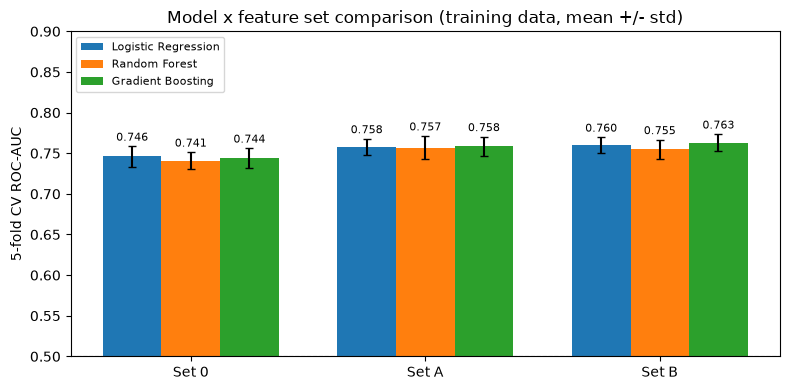

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
width = 0.25
for i, m in enumerate(MODELS):
    sub = cv_results[cv_results["model"] == m].set_index("feature_set").loc[FEATURE_SETS]
    xs = [j + (i - 1) * width for j in range(len(FEATURE_SETS))]
    bars = ax.bar(xs, sub["cv_roc_auc_mean"], width, yerr=sub["cv_roc_auc_std"],
                  capsize=3, label=m)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(range(len(FEATURE_SETS)), FEATURE_SETS)
ax.set_ylim(0.5, 0.9)
ax.axhline(0.5, color="grey", lw=0.8, ls="--")
ax.set_ylabel("5-fold CV ROC-AUC")
ax.set_title("Model x feature set comparison (training data, mean +/- std)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 6. How to read these results
- **Set 0 -> Set A:** gain from adding basic wearable activity data (RQ2).
- **Set A -> Set B:** gain from feature engineering (intensity, sedentary, rhythm, PCA, K-means).
- **Between models:** whether non-linear ensembles (RF, GB) beat the linear baseline (LR).
- These are **cross-validation** scores on training data. The final, unbiased numbers come from the held-out test set (Part 4 / Member 4).

---
# Part 4: Predictions and handover to Member 4

In [7]:
import joblib
import numpy as np
from sklearn.metrics import roc_auc_score
from src.models.pipeline import best_f1_threshold, oof_probabilities

OUT_DATA = ROOT / "data" / "processed"
OUT_MODELS = ROOT / "models"
OUT_FIGS = ROOT / "reports" / "figures"
for d in (OUT_DATA, OUT_MODELS, OUT_FIGS):
    d.mkdir(parents=True, exist_ok=True)

## 7. Decision threshold tau (training data only)
A model outputs a probability p. To turn it into 0/1 we need a threshold tau (predict 1 if p >= tau).
As in proposal section 4.8, tau is chosen to **maximise F1 on out-of-fold training predictions**,
so the test set is still not used.

In [8]:
oof_rows = []
for (s, m), search in searches.items():
    X_train, _, y_train, _ = data[s]
    p_oof = oof_probabilities(search, X_train, y_train)
    tau = best_f1_threshold(y_train, p_oof)
    cv_results.loc[(cv_results.feature_set == s) & (cv_results.model == m), "threshold_f1"] = tau
    oof_rows.append(pd.DataFrame({"SEQN": X_train.index, "feature_set": s, "model": m,
                                  "y_true": y_train.to_numpy(), "y_proba": p_oof,
                                  "y_pred": (p_oof >= tau).astype(int)}))
    print(f"{s:6s} | {m:20s} | tau = {tau:.3f}")
oof_predictions = pd.concat(oof_rows, ignore_index=True)

Set 0  | Logistic Regression  | tau = 0.377


Set 0  | Random Forest        | tau = 0.360


Set 0  | Gradient Boosting    | tau = 0.385


Set A  | Logistic Regression  | tau = 0.388


Set A  | Random Forest        | tau = 0.443


Set A  | Gradient Boosting    | tau = 0.352


Set B  | Logistic Regression  | tau = 0.396


Set B  | Random Forest        | tau = 0.387


Set B  | Gradient Boosting    | tau = 0.346


## 8. Predict the held-out test set (used ONCE)
All hyperparameters and thresholds are now fixed. Each tuned pipeline predicts the 918 test participants.
`y_proba` = P(risk = 1), `y_pred` = 0/1 using that model's tau.

In [9]:
test_rows = []
for (s, m), search in searches.items():
    _, X_test, _, y_test = data[s]
    tau = cv_results.loc[(cv_results.feature_set == s) & (cv_results.model == m), "threshold_f1"].item()
    p_test = search.predict_proba(X_test)[:, 1]
    test_rows.append(pd.DataFrame({"SEQN": X_test.index, "feature_set": s, "model": m,
                                   "y_true": y_test.to_numpy(), "y_proba": p_test,
                                   "y_pred": (p_test >= tau).astype(int)}))
test_predictions = pd.concat(test_rows, ignore_index=True)
display(test_predictions.head())

# Quick sanity check only. Full evaluation (CIs, PR-AUC, F1, calibration) is Member 4's task.
sanity = (test_predictions.groupby(["model", "feature_set"])
          .apply(lambda g: roc_auc_score(g["y_true"], g["y_proba"]), include_groups=False)
          .unstack().loc[MODELS, FEATURE_SETS])
display(sanity.style.format("{:.3f}").set_caption("Sanity check: test ROC-AUC"))

,SEQN,feature_set,model,y_true,y_proba,y_pred
0,62164,Set 0,Logistic Regression,0,0.409070,1
1,62177,Set 0,Logistic Regression,0,0.467926,1
2,62224,Set 0,Logistic Regression,0,0.237652,0
3,62226,Set 0,Logistic Regression,1,0.824461,1
4,62288,Set 0,Logistic Regression,0,0.237652,0


feature_set,Set 0,Set A,Set B
model,,,
Logistic Regression,0.732,0.751,0.761
Random Forest,0.726,0.743,0.744
Gradient Boosting,0.733,0.751,0.754


## 9. Save handover files for Member 4
| File | Contents | In Git? |
|---|---|---|
| `data/processed/test_predictions.parquet` | SEQN, feature_set, model, y_true, y_proba, y_pred (test set) | yes |
| `data/processed/oof_predictions.parquet` | Same columns for the training set (out-of-fold) | yes |
| `data/processed/cv_results_summary.parquet` | CV ROC-AUC mean/std, best hyperparameters, tau, tuning time | yes |
| `models/tuned_pipelines.joblib` | `{feature_set: {model: fitted Pipeline}}` | no (`.gitignore`), share via Google Drive |
| `reports/figures/m3_cv_model_comparison.png` | Bar chart from section 5 | yes |

In [10]:
summary = cv_results.copy()
summary["best_params"] = summary["best_params"].astype(str)   # dict -> text for parquet

test_predictions.to_parquet(OUT_DATA / "test_predictions.parquet", index=False)
oof_predictions.to_parquet(OUT_DATA / "oof_predictions.parquet", index=False)
summary.to_parquet(OUT_DATA / "cv_results_summary.parquet", index=False)

pipelines = {s: {m: searches[(s, m)].best_estimator_ for m in MODELS} for s in FEATURE_SETS}
joblib.dump(pipelines, OUT_MODELS / "tuned_pipelines.joblib")

fig.savefig(OUT_FIGS / "m3_cv_model_comparison.png", dpi=300, bbox_inches="tight")

for f in ["data/processed/test_predictions.parquet", "data/processed/oof_predictions.parquet",
          "data/processed/cv_results_summary.parquet", "models/tuned_pipelines.joblib",
          "reports/figures/m3_cv_model_comparison.png"]:
    print(f"saved  {f:45s} {(ROOT / f).stat().st_size / 1024:8.1f} KB")
display(summary)

saved  data/processed/test_predictions.parquet           82.2 KB
saved  data/processed/oof_predictions.parquet           362.2 KB
saved  data/processed/cv_results_summary.parquet          5.3 KB
saved  models/tuned_pipelines.joblib                  16771.8 KB
saved  reports/figures/m3_cv_model_comparison.png       100.8 KB


,feature_set,model,cv_roc_auc_mean,cv_roc_auc_std,best_params,tuning_seconds,threshold_f1
0,Set 0,Logistic Regression,0.746132,0.012588,"{'C': 0.1, 'l1_ratio': 1.0}",11.2,0.376820
1,Set 0,Random Forest,0.740922,0.010510,"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}",19.7,0.360324
2,Set 0,Gradient Boosting,0.744294,0.012044,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}",5.4,0.385101
3,Set A,Logistic Regression,0.757683,0.010222,"{'C': 0.1, 'l1_ratio': 1.0}",0.4,0.388306
4,Set A,Random Forest,0.757037,0.014345,"{'max_depth': 16, 'max_features': 0.3, 'min_samples_leaf': 10, 'n_estimators': 300}",18.4,0.442618
5,Set A,Gradient Boosting,0.758445,0.012030,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}",9.1,0.351693
6,Set B,Logistic Regression,0.759942,0.009876,"{'C': 1, 'l1_ratio': 1.0}",8.4,0.396482
7,Set B,Random Forest,0.754806,0.011954,"{'max_depth': 8, 'max_features': 0.3, 'min_samples_leaf': 10, 'n_estimators': 300}",48.6,0.386903
8,Set B,Gradient Boosting,0.762874,0.010719,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}",31.6,0.346476


## 10. Handover checks
The test set must have one row per participant per (set, model), and no participant may appear in both train and test.

In [11]:
assert set(test_predictions.SEQN).isdisjoint(oof_predictions.SEQN), "train/test overlap!"
assert test_predictions.groupby(["feature_set", "model"]).size().eq(len(data["Set B"][1])).all()
assert test_predictions[["y_proba", "y_pred"]].notna().all().all()
assert test_predictions.y_proba.between(0, 1).all()
reloaded = joblib.load(OUT_MODELS / "tuned_pipelines.joblib")
assert set(reloaded) == set(FEATURE_SETS) and all(set(v) == set(MODELS) for v in reloaded.values())
print("All handover checks passed.")

All handover checks passed.
